# Прогноз временного ряда

Прогноз на 168 часов, тест — последние две недели.
[Данные UCI](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume):
автомобильный поток на I-94, а не пассажиры метро. Наблюдения почасовые.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
from IPython.display import display
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (14, 4)
pd.set_option('display.max_columns', 20)

## Данные

In [2]:
data_dir = Path('time/data') if Path('time').is_dir() else Path('data')
data_dir.mkdir(exist_ok=True, parents=True)
file = data_dir / 'Metro_Interstate_Traffic_Volume.csv.gz'

if not file.exists():
    url = 'https://archive.ics.uci.edu/static/public/492/metro%2Binterstate%2Btraffic%2Bvolume.zip'
    archive = data_dir / 'metro.zip'
    urlretrieve(url, archive)
    with ZipFile(archive) as z:
        file.write_bytes(z.read(file.name))
    archive.unlink()

df = pd.read_csv(file, usecols=['traffic_volume', 'date_time', 'holiday', 'temp'],
                 parse_dates=['date_time'], keep_default_na=False)
df.head()

,holiday,temp,date_time,traffic_volume
0,None,288.28,2012-10-02 09:00:00,5545
1,None,289.36,2012-10-02 10:00:00,4516
2,None,289.58,2012-10-02 11:00:00,4767
3,None,290.13,2012-10-02 12:00:00,5026
4,None,291.14,2012-10-02 13:00:00,4918


In [3]:
df.info()
display(df.describe(include='all'))
display(df.isna().sum().rename('Пропуски'))
display(df['holiday'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   holiday         48204 non-null  str           
 1   temp            48204 non-null  float64       
 2   date_time       48204 non-null  datetime64[us]
 3   traffic_volume  48204 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 1.5 MB


,holiday,temp,date_time,traffic_volume
count,48204,48204.000000,48204,48204.000000
unique,12,NaN,NaN,NaN
top,None,NaN,NaN,NaN
freq,48143,NaN,NaN,NaN
mean,NaN,281.205870,2016-01-05 10:46:16.773711,3259.818355
min,NaN,0.000000,2012-10-02 09:00:00,0.000000
25%,NaN,272.160000,2014-02-06 11:45:00,1193.000000
50%,NaN,282.450000,2016-06-11 03:30:00,3380.000000
75%,NaN,291.806000,2017-08-11 06:00:00,4933.000000
max,NaN,310.070000,2018-09-30 23:00:00,7280.000000


holiday           0
temp              0
date_time         0
traffic_volume    0
Name: Пропуски, dtype: int64

holiday
None                         48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64

In [4]:
print('Повторы по четырём столбцам:', df.duplicated().sum())
print('Повторы date_time:', df['date_time'].duplicated().sum())
display(df[df['date_time'].duplicated(keep=False)].head(8))

steps = df['date_time'].drop_duplicates().sort_values().diff().dropna()
display(steps.value_counts().head(8).rename('Количество интервалов'))
display(steps.nlargest(5).rename('Самые длинные интервалы'))

Повторы по четырём столбцам: 7551
Повторы date_time: 7629


,holiday,temp,date_time,traffic_volume
178,None,281.25,2012-10-10 07:00:00,6793
179,None,281.25,2012-10-10 07:00:00,6793
180,None,280.10,2012-10-10 08:00:00,6283
181,None,280.10,2012-10-10 08:00:00,6283
182,None,279.61,2012-10-10 09:00:00,5680
183,None,279.61,2012-10-10 09:00:00,5680
269,None,282.43,2012-10-14 09:00:00,2685
270,None,282.43,2012-10-14 09:00:00,2685


date_time
0 days 01:00:00    37986
0 days 02:00:00     2192
0 days 03:00:00      201
0 days 04:00:00       59
0 days 05:00:00       33
0 days 06:00:00       17
0 days 08:00:00       13
0 days 10:00:00       13
Name: Количество интервалов, dtype: int64

15971   307 days 19:00:00
9661     10 days 03:00:00
15978     4 days 22:00:00
14012     4 days 21:00:00
19159     3 days 21:00:00
Name: Самые длинные интервалы, dtype: timedelta64[us]

Повторы времени связаны в том числе с несколькими описаниями погоды.
Оставим первую запись каждого часа. `holiday = None` — обычный день.
Нулевая температура в Кельвинах — ошибка, заменим её пропуском.

In [5]:
holiday_dates = pd.DatetimeIndex(df.loc[df['holiday'].ne('None'), 'date_time']).normalize().unique()

data = (df.drop_duplicates().drop_duplicates('date_time')
          .set_index('date_time').sort_index())
data['temp'] = data['temp'].where(data['temp'] > 0) - 273.15
index = pd.date_range(data.index.min(), data.index.max(), freq='h', name='date_time')
data = data.reindex(index)
observed = data['traffic_volume'].notna()
data['holiday'] = index.normalize().isin(holiday_dates).astype(int)

missing = ~observed
gap_id = missing.ne(missing.shift()).cumsum()
gaps = (pd.DataFrame({'start': index, 'end': index, 'hours': missing.astype(int)})
        .loc[missing.to_numpy()].groupby(gap_id[missing].to_numpy())
        .agg(start=('start', 'min'), end=('end', 'max'), hours=('hours', 'sum')))

print('Часов на сетке:', len(data))
print('Добавлено часов:', missing.sum())
print('Ошибок температуры:', df['temp'].le(0).sum())
display(gaps.sort_values('hours', ascending=False).head())

Часов на сетке: 52551
Добавлено часов: 11976
Ошибок температуры: 10


,start,end,hours
1792,2014-08-08 02:00:00,2015-06-11 19:00:00,7386
1328,2013-10-27 02:00:00,2013-11-06 03:00:00,242
1804,2015-06-14 21:00:00,2015-06-19 17:00:00,117
1566,2014-04-29 09:00:00,2014-05-04 04:00:00,116
2048,2015-10-23 12:00:00,2015-10-27 07:00:00,92


## EDA

Последние 336 часов оставим для теста. Перед ними — четыре недели валидации:
первые две для выбора истории и сравнения моделей, следующие две для оценки интервалов.

In [6]:
HORIZON = 24 * 7
test_start = data.index[-2 * HORIZON]
validation_start = test_start - pd.Timedelta(weeks=4)
calibration_start = test_start - pd.Timedelta(weeks=2)

eda = data.loc[data.index < validation_start].copy()
display(pd.DataFrame({
    'Начало': [data.index.min(), validation_start, calibration_start, test_start],
    'Конец': [validation_start - pd.Timedelta(hours=1),
              calibration_start - pd.Timedelta(hours=1),
              test_start - pd.Timedelta(hours=1), data.index.max()]
}, index=['Обучение', 'Выбор модели', 'Калибровка', 'Тест']))

,Начало,Конец
Обучение,2012-10-02 09:00:00,2018-08-19 23:00:00
Выбор модели,2018-08-20 00:00:00,2018-09-02 23:00:00
Калибровка,2018-09-03 00:00:00,2018-09-16 23:00:00
Тест,2018-09-17 00:00:00,2018-09-30 23:00:00


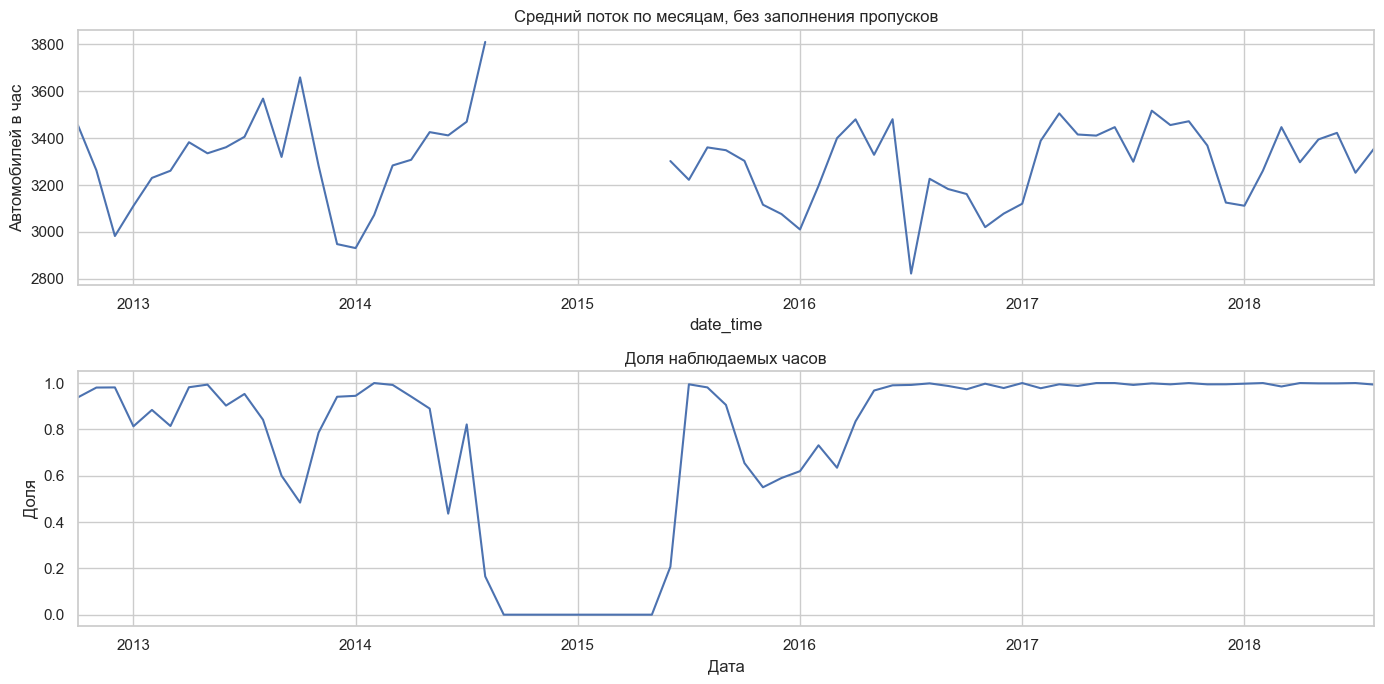

,count,mean,std
date_time,,,
2012,2103,3226.7,2005.6
2013,7294,3309.6,2030.7
2014,4501,3270.1,1992.7
2015,3593,3258.0,1970.8
2016,7838,3193.7,1943.8
2017,8713,3376.6,1982.6
2018,5526,3315.9,1975.1


In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
eda['traffic_volume'].resample('MS').mean().plot(ax=axes[0])
axes[0].set(title='Средний поток по месяцам, без заполнения пропусков', ylabel='Автомобилей в час')
eda['traffic_volume'].notna().resample('MS').mean().plot(ax=axes[1])
axes[1].set(title='Доля наблюдаемых часов', ylabel='Доля', xlabel='Дата')
plt.tight_layout()
plt.show()

display(eda['traffic_volume'].groupby(eda.index.year).agg(['count', 'mean', 'std']).round(1))

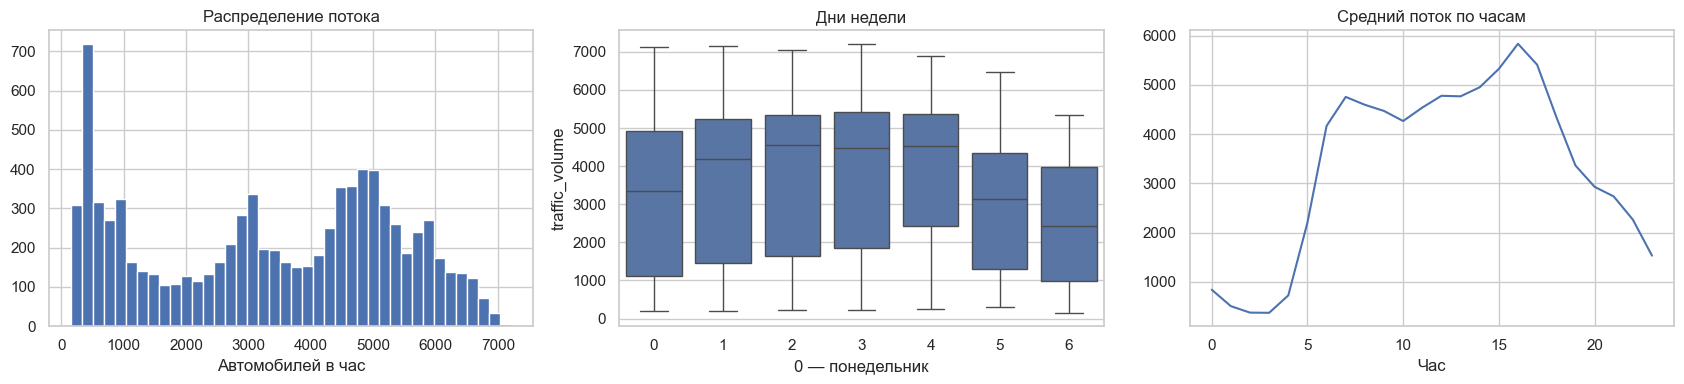

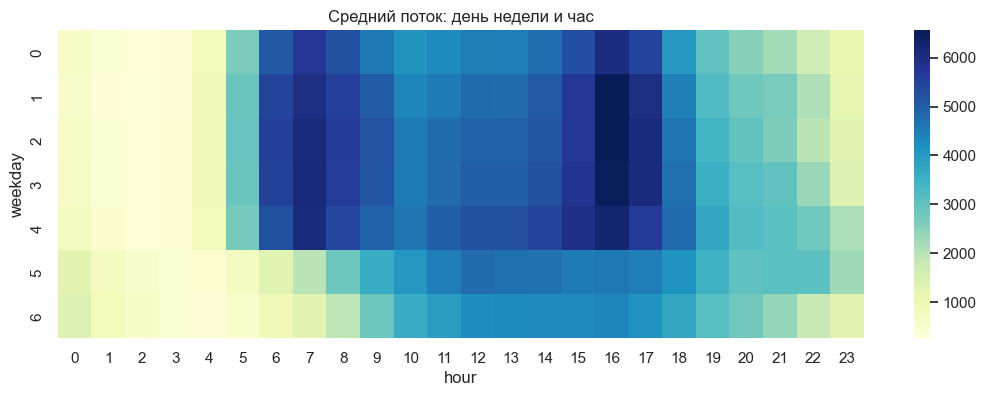

In [8]:
recent = eda.loc[eda.index >= eda.index.max() - pd.Timedelta(weeks=52)].copy()
recent['weekday'] = recent.index.dayofweek
recent['hour'] = recent.index.hour

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
recent['traffic_volume'].hist(bins=40, ax=axes[0])
axes[0].set(title='Распределение потока', xlabel='Автомобилей в час')
sns.boxplot(data=recent, x='weekday', y='traffic_volume', ax=axes[1], showfliers=False)
axes[1].set(title='Дни недели', xlabel='0 — понедельник')
recent.groupby('hour')['traffic_volume'].mean().plot(ax=axes[2])
axes[2].set(title='Средний поток по часам', xlabel='Час')
plt.tight_layout()
plt.show()

plt.figure(figsize=(13, 4))
sns.heatmap(recent.groupby(['weekday', 'hour'])['traffic_volume'].mean().unstack(), cmap='YlGnBu')
plt.title('Средний поток: день недели и час')
plt.show()

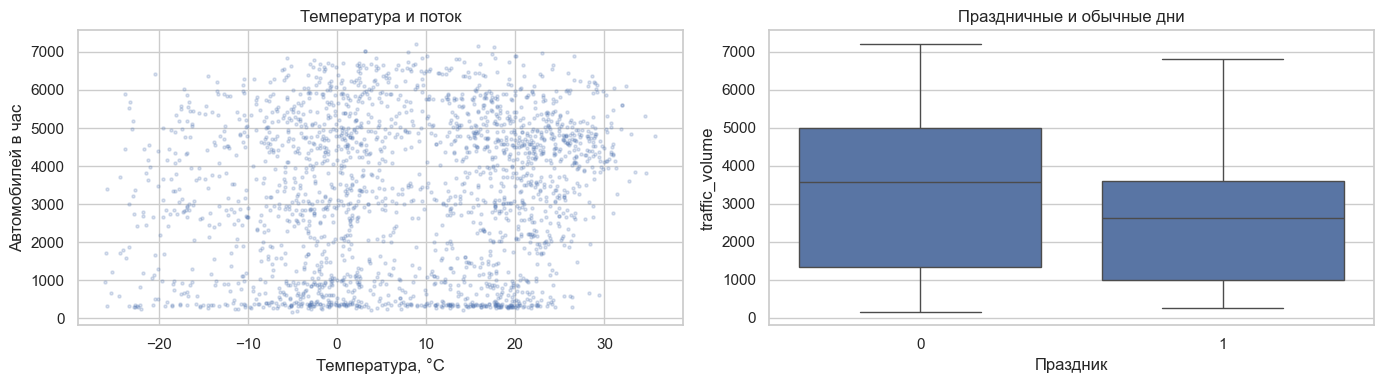

1      0.914754
24     0.865529
48     0.743959
168    0.943949
336    0.943412
Name: Автокорреляция, dtype: float64

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sample = recent.dropna(subset=['temp', 'traffic_volume']).iloc[::4]
axes[0].scatter(sample['temp'], sample['traffic_volume'], s=5, alpha=0.2)
axes[0].set(title='Температура и поток', xlabel='Температура, °C', ylabel='Автомобилей в час')
sns.boxplot(data=recent, x='holiday', y='traffic_volume', ax=axes[1], showfliers=False)
axes[1].set(title='Праздничные и обычные дни', xlabel='Праздник')
plt.tight_layout()
plt.show()

display(pd.Series({lag: recent['traffic_volume'].autocorr(lag=lag)
                   for lag in [1, 24, 48, 168, 336]}, name='Автокорреляция'))

Виден суточный и недельный рисунок: ночью поток ниже, по выходным меняется профиль дня.
В старой части ряда есть большой разрыв, а последние годы заполнены заметно лучше.
Сравним последние 8, 13, 26 и 52 недели на валидации.

## Подготовка ряда

Интерполяцию выполняем отдельно для истории, доступной на дату каждого прогноза.
На равномерной сетке используем [линейную интерполяцию](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.interpolate.html).
Крайний пропуск заполняем последним известным значением.
Для метрик и целевых значений обучения берём только реальные наблюдения.

,До,После
holiday,0,0
temp,11985,0
traffic_volume,11975,0


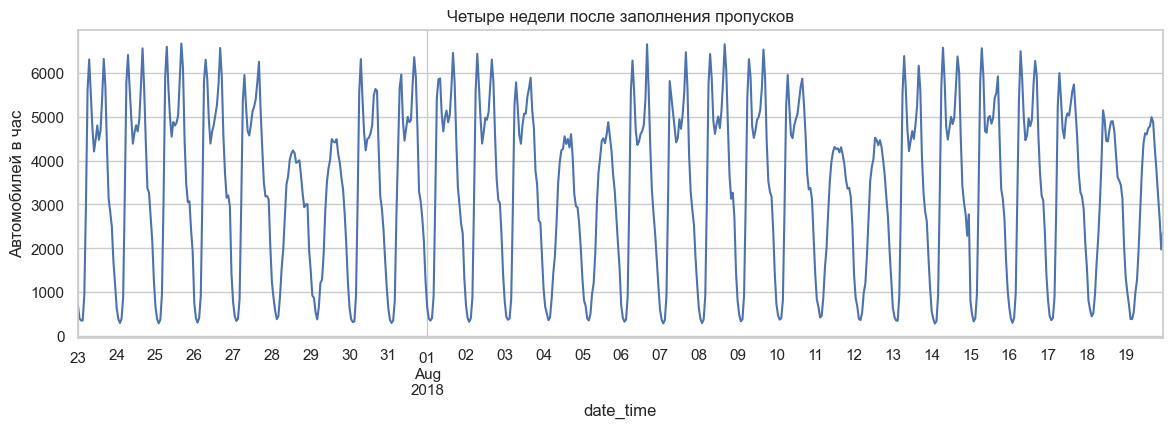

In [10]:
def prepare(history):
    result = history.copy()
    columns = ['traffic_volume', 'temp']
    result[columns] = result[columns].interpolate(method='linear', limit_area='inside').ffill()
    return result


filled = prepare(eda)
assert filled.index.is_unique
assert filled.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
assert filled[['traffic_volume', 'temp']].notna().all().all()

display(pd.DataFrame({'До': eda.isna().sum(), 'После': filled.isna().sum()}))
filled['traffic_volume'].tail(4 * HORIZON).plot(title='Четыре недели после заполнения пропусков')
plt.ylabel('Автомобилей в час')
plt.show()

## Baseline

Среднее по дню недели и часу. Основная метрика — MAE, дополнительно RMSE и WAPE.
WAPE подходит для ряда с нулевыми значениями.

In [11]:
def metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true)
    y_true, y_pred = y_true[mask], y_pred[mask]
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'WAPE, %': 100 * np.abs(y_true - y_pred).sum() / np.abs(y_true).sum()
    }


def baseline(history, index, weeks):
    train = prepare(history).tail(weeks * HORIZON).copy()
    train['weekday'] = train.index.dayofweek
    train['hour'] = train.index.hour
    means = train.groupby(['weekday', 'hour'])['traffic_volume'].mean()
    keys = pd.MultiIndex.from_arrays([index.dayofweek, index.hour])
    return pd.Series(means.reindex(keys).to_numpy(), index=index)


selection_origins = pd.date_range(validation_start, periods=2, freq='7D')
calibration_origins = pd.date_range(calibration_start, periods=2, freq='7D')
test_origins = pd.date_range(test_start, periods=2, freq='7D')

window_scores = []
for weeks in [8, 13, 26, 52]:
    for origin in selection_origins:
        history = data.loc[data.index < origin]
        index = pd.date_range(origin, periods=HORIZON, freq='h')
        pred = baseline(history, index, weeks)
        window_scores.append({'weeks': weeks, 'origin': origin,
                              **metrics(data.loc[index, 'traffic_volume'], pred)})

window_scores = pd.DataFrame(window_scores).groupby('weeks')[['MAE', 'RMSE', 'WAPE, %']].mean()
window_scores = window_scores.sort_values('MAE')
train_weeks = int(window_scores.index[0])
display(window_scores.round(2))
print('Оставляем недель для обучения:', train_weeks)

,MAE,RMSE,"WAPE, %"
weeks,,,
26,180.48,242.55,5.23
52,186.64,253.80,5.40
13,208.30,281.75,6.03
8,233.07,313.40,6.75


Оставляем недель для обучения: 26


## Дополнительные признаки и модели

День недели, час, месяц, праздник и циклические календарные признаки.
Лаги потока и температуры — от 168 часов: для всей следующей недели они уже известны.
Для лагов оставляем ещё четыре недели перед обучающим окном.
Фактическая температура будущей недели не используется.

In [12]:
def make_features(history, future_index=None):
    frame = prepare(history)
    if future_index is not None:
        frame = frame.reindex(frame.index.append(future_index))
    index = frame.index
    X = pd.DataFrame(index=index)
    X['weekday'] = index.dayofweek
    X['hour'] = index.hour
    X['week_hour'] = index.dayofweek * 24 + index.hour
    X['month'] = index.month
    X['weekend'] = (index.dayofweek >= 5).astype(int)
    known_holidays = index.normalize().isin(holiday_dates)
    future_holidays = USFederalHolidayCalendar().holidays(data.index.max().normalize() + pd.Timedelta(days=1),
                                                        index.max().normalize())
    X['holiday'] = (known_holidays | index.normalize().isin(future_holidays)).astype(int)
    for name, values, period in [('hour', index.hour, 24),
                                  ('week', index.dayofweek * 24 + index.hour, 168),
                                  ('year', index.dayofyear, 365.25)]:
        X[name + '_sin'] = np.sin(2 * np.pi * values / period)
        X[name + '_cos'] = np.cos(2 * np.pi * values / period)
    for lag in [168, 336, 504, 672]:
        X[f'lag_{lag}'] = frame['traffic_volume'].shift(lag)
        X[f'temp_lag_{lag}'] = frame['temp'].shift(lag)
    lag_columns = [f'lag_{lag}' for lag in [168, 336, 504, 672]]
    X['week_mean'] = X[lag_columns].mean(axis=1)
    X['week_std'] = X[lag_columns].std(axis=1)
    X['rolling_24'] = frame['traffic_volume'].shift(168).rolling(24).mean()
    X['rolling_168'] = frame['traffic_volume'].shift(168).rolling(168).mean()
    return X


history = data.loc[data.index < validation_start].tail((train_weeks + 4) * HORIZON)
X_example = make_features(history).tail(train_weeks * HORIZON)
display(X_example.head())

,weekday,hour,week_hour,month,weekend,holiday,hour_sin,hour_cos,week_sin,week_cos,...,lag_336,temp_lag_336,lag_504,temp_lag_504,lag_672,temp_lag_672,week_mean,week_std,rolling_24,rolling_168
date_time,,,,,,,,,,,,,,,,,,,,,
2018-02-19 00:00:00,0,0,0,2,0,1,0.000000,1.000000,0.000000,1.000000,...,836.0,-19.65,482.0,-11.61,486.0,1.79,576.50,173.215665,2532.500000,3363.267857
2018-02-19 01:00:00,0,1,1,2,0,1,0.258819,0.965926,0.037391,0.999301,...,505.0,-20.15,335.0,-12.36,337.0,1.53,365.75,95.782305,2512.708333,3361.964286
2018-02-19 02:00:00,0,2,2,2,0,1,0.500000,0.866025,0.074730,0.997204,...,411.0,-20.78,230.0,-12.72,254.0,1.13,281.25,87.236747,2501.958333,3360.886905
2018-02-19 03:00:00,0,3,3,2,0,1,0.707107,0.707107,0.111964,0.993712,...,429.0,-21.00,353.0,-13.29,325.0,0.85,354.50,52.646621,2502.333333,3360.184524
2018-02-19 04:00:00,0,4,4,2,0,1,0.866025,0.500000,0.149042,0.988831,...,925.0,-20.93,888.0,-13.71,897.0,0.78,879.75,49.728429,2525.458333,3359.494048


In [13]:
def make_model(name, columns):
    if name == 'Ridge':
        categorical = ['week_hour', 'month']
        numeric = [column for column in columns if column not in categorical]
        transform = ColumnTransformer([
            ('calendar', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical),
            ('numeric', StandardScaler(), numeric)
        ])
        return make_pipeline(transform, Ridge(alpha=100))
    if name == 'Random forest':
        return RandomForestRegressor(n_estimators=150, max_depth=16,
                                     min_samples_leaf=3, max_features=0.8,
                                     random_state=42, n_jobs=-1)
    if name == 'Gradient boosting':
        return GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                         max_depth=3, min_samples_leaf=10,
                                         random_state=42)
    raise ValueError(name)


def forecast(history, index, name, weeks):
    if name == 'Baseline':
        return baseline(history, index, weeks), None
    history = history.tail((weeks + 4) * HORIZON)
    if name == 'Seasonal naive':
        series = prepare(history)['traffic_volume']
        prediction = series.reindex(index - pd.Timedelta(weeks=1)).to_numpy()
        return pd.Series(prediction, index=index), None
    X = make_features(history, index)
    train_index = history.index[-weeks * HORIZON:]
    train_index = train_index[history.loc[train_index, 'traffic_volume'].notna().to_numpy()]
    X_train = X.loc[train_index].dropna()
    y_train = history.loc[X_train.index, 'traffic_volume']
    X_future = X.loc[index]
    assert X_future.notna().all().all()
    assert X_train.index.max() < index.min()
    assert index.max() - pd.Timedelta(hours=168) <= history.index.max()
    model = make_model(name, X_train.columns)
    model.fit(X_train, y_train)
    prediction = np.maximum(model.predict(X_future), 0)
    return pd.Series(prediction, index=index), model


def backtest(origins, names, weeks):
    results = []
    predictions = []
    for origin in origins:
        history = data.loc[data.index < origin]
        index = pd.date_range(origin, periods=HORIZON, freq='h')
        for name in names:
            pred, _ = forecast(history, index, name, weeks)
            actual = data.loc[index, 'traffic_volume']
            results.append({'origin': origin, 'model': name, **metrics(actual, pred)})
            predictions.append(pd.DataFrame({'actual': actual, 'prediction': pred,
                                             'model': name, 'origin': origin}))
    return pd.DataFrame(results), pd.concat(predictions)

In [14]:
model_names = ['Baseline', 'Seasonal naive', 'Ridge', 'Random forest', 'Gradient boosting']
validation_scores, validation_predictions = backtest(selection_origins, model_names, train_weeks)
validation_table = (validation_scores.groupby('model')[['MAE', 'RMSE', 'WAPE, %']]
                   .mean().sort_values('MAE'))
validation_best_name = validation_table.index[0]
display(validation_table.round(2))
print('Лучшая модель на валидации:', validation_best_name)

,MAE,RMSE,"WAPE, %"
model,,,
Baseline,180.48,242.55,5.23
Seasonal naive,194.28,276.13,5.63
Gradient boosting,269.80,459.63,7.82
Random forest,273.23,477.08,7.92
Ridge,273.74,390.64,7.93


Лучшая модель на валидации: Baseline


## Интервалы и итоговая проверка

На двух следующих валидационных неделях оценим 95-й процентиль абсолютных ошибок
каждой модели. Получим приближённый 95% поточечный прогнозный интервал.
Из-за зависимости ошибок во времени точное покрытие 95% не гарантируется.

На тесте делаем два прогноза по 168 часов. Перед второй неделей первая уже известна,
модели переобучаются. Длину истории и параметры моделей по тесту не меняем.
По условию задания итоговую модель выберем по MAE на этих двух неделях.
Поэтому тест служит для выбора, его метрики не являются независимой оценкой выбранной модели.

In [15]:
calibration_scores, calibration_predictions = backtest(calibration_origins, model_names, train_weeks)
alpha = 0.05
radii = {}
for name, part in calibration_predictions.groupby('model'):
    errors = (part['actual'] - part['prediction']).dropna().abs()
    level = min(np.ceil((len(errors) + 1) * (1 - alpha)) / len(errors), 1)
    radii[name] = np.quantile(errors, level, method='higher')
display(pd.Series(radii, name='Полуширина интервала').round(1))
display(calibration_scores.round({'MAE': 2, 'RMSE': 2, 'WAPE, %': 2}))

Baseline              761.1
Gradient boosting     668.0
Random forest         584.5
Ridge                 758.2
Seasonal naive       1761.0
Name: Полуширина интервала, dtype: float64

,origin,model,MAE,RMSE,"WAPE, %"
0,2018-09-03,Baseline,335.89,697.16,10.67
1,2018-09-03,Seasonal naive,393.52,792.94,12.50
2,2018-09-03,Ridge,342.77,580.45,10.89
3,2018-09-03,Random forest,307.16,524.63,9.76
4,2018-09-03,Gradient boosting,285.11,476.45,9.06
5,2018-09-10,Baseline,183.92,281.41,5.40
6,2018-09-10,Seasonal naive,352.61,798.13,10.35
7,2018-09-10,Ridge,210.45,277.37,6.18
8,2018-09-10,Random forest,174.12,263.40,5.11
9,2018-09-10,Gradient boosting,185.56,280.69,5.45


In [16]:
test_scores, test_predictions = backtest(test_origins, model_names, train_weeks)
test_table = pd.DataFrame({
    name: metrics(part['actual'], part['prediction'])
    for name, part in test_predictions.groupby('model')
}).T.sort_values('MAE')
test_table['Лучше baseline, %'] = 100 * (1 - test_table['MAE'] / test_table.loc['Baseline', 'MAE'])
best_name = test_table.index[0]
radius = radii[best_name]
display(test_table.round(2))
display(test_scores.sort_values(['origin', 'MAE']).round({'MAE': 2, 'RMSE': 2, 'WAPE, %': 2}))
print('Модель для финального прогноза:', best_name)

,MAE,RMSE,"WAPE, %","Лучше baseline, %"
Random forest,172.59,268.42,5.12,14.57
Baseline,202.01,298.69,5.99,0.00
Seasonal naive,205.86,333.91,6.10,-1.91
Ridge,224.28,323.58,6.65,-11.02
Gradient boosting,224.61,317.65,6.66,-11.19


,origin,model,MAE,RMSE,"WAPE, %"
3,2018-09-17,Random forest,184.59,269.17,5.50
1,2018-09-17,Seasonal naive,209.85,335.48,6.25
0,2018-09-17,Baseline,222.72,312.98,6.63
2,2018-09-17,Ridge,230.18,317.44,6.85
4,2018-09-17,Gradient boosting,273.06,357.07,8.13
8,2018-09-24,Random forest,160.59,267.67,4.74
9,2018-09-24,Gradient boosting,176.16,272.59,5.20
5,2018-09-24,Baseline,181.31,283.69,5.35
6,2018-09-24,Seasonal naive,201.88,332.33,5.96
7,2018-09-24,Ridge,218.38,329.62,6.45


Модель для финального прогноза: Random forest


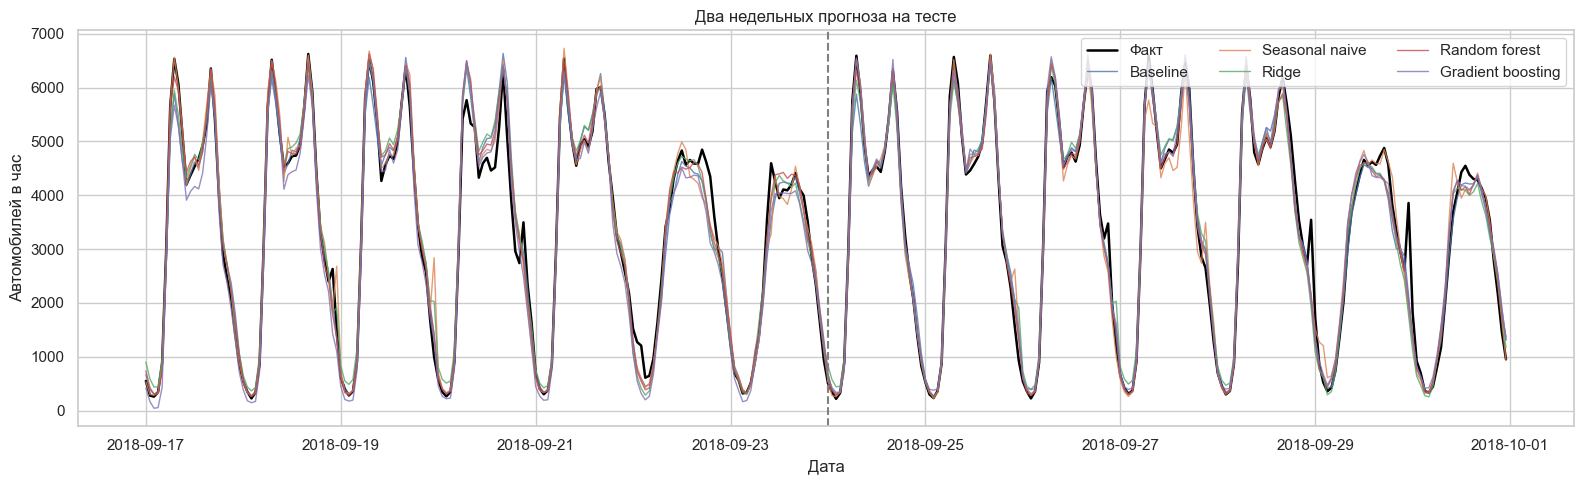

In [17]:
fig, ax = plt.subplots(figsize=(16, 5))
actual = data.loc[data.index >= test_start, 'traffic_volume']
ax.plot(actual.index, actual, color='black', label='Факт', linewidth=1.8)
for name in model_names:
    part = test_predictions.loc[test_predictions['model'].eq(name)]
    ax.plot(part.index, part['prediction'], label=name, alpha=0.8, linewidth=1)
ax.axvline(test_origins[1], color='grey', linestyle='--')
ax.set(title='Два недельных прогноза на тесте', ylabel='Автомобилей в час', xlabel='Дата')
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

Покрытие 95% интервалом на тесте: 95.2%
Средняя ширина: 1142.5
Random forest: MAE = 172.6; улучшение к baseline = 14.6%


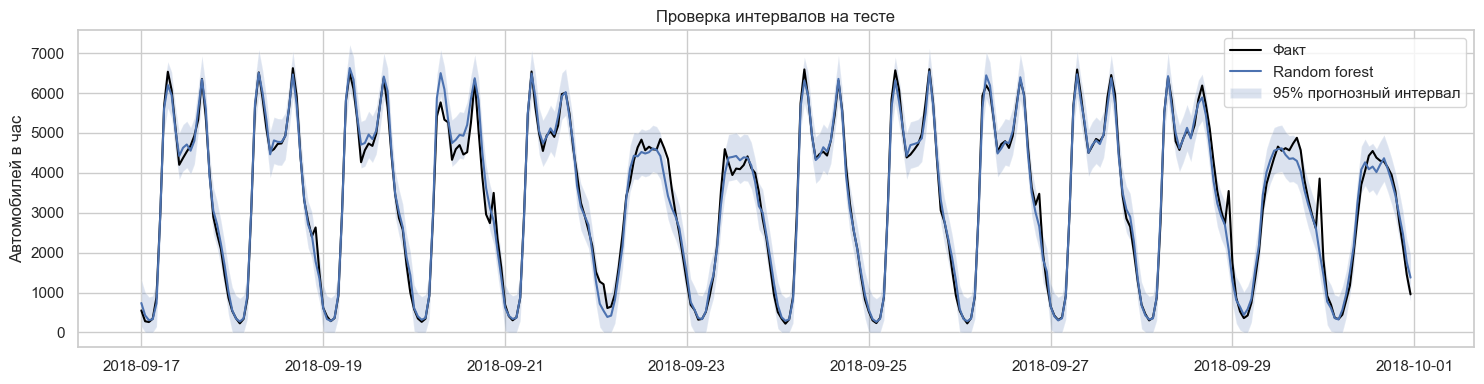

In [18]:
selected_test = test_predictions.loc[test_predictions['model'].eq(best_name)].copy()
selected_test['lower_95'] = (selected_test['prediction'] - radius).clip(lower=0)
selected_test['upper_95'] = selected_test['prediction'] + radius
valid = selected_test['actual'].notna()
coverage = selected_test.loc[valid, 'actual'].between(
    selected_test.loc[valid, 'lower_95'], selected_test.loc[valid, 'upper_95']).mean()

print(f'Покрытие 95% интервалом на тесте: {coverage:.1%}')
print('Средняя ширина:', round((selected_test['upper_95'] - selected_test['lower_95']).mean(), 1))
gain = test_table.loc[best_name, 'Лучше baseline, %']
print(f'{best_name}: MAE = {test_table.loc[best_name, "MAE"]:.1f}; улучшение к baseline = {gain:.1f}%')

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(selected_test.index, selected_test['actual'], color='black', label='Факт')
ax.plot(selected_test.index, selected_test['prediction'], label=best_name)
ax.fill_between(selected_test.index, selected_test['lower_95'], selected_test['upper_95'],
                alpha=0.2, label='95% прогнозный интервал')
ax.set(title='Проверка интервалов на тесте', ylabel='Автомобилей в час')
ax.legend()
plt.tight_layout()
plt.show()

## Прогноз на следующую неделю

Переобучим выбранную модель, включив последние две недели в доступную историю.
Калибровку интервалов оставим прежней. Будущие праздники берём из календаря,
температурные признаки — только из прошлого.

In [19]:
future_index = pd.date_range(data.index.max() + pd.Timedelta(hours=1), periods=HORIZON,
                             freq='h', name='date_time')
future_pred, final_model = forecast(data, future_index, best_name, train_weeks)
future = pd.DataFrame({
    'traffic_volume': future_pred,
    'lower_95': (future_pred - radius).clip(lower=0),
    'upper_95': future_pred + radius
})
assert len(future) == 168
assert future.notna().all().all()
assert future['lower_95'].le(future['traffic_volume']).all()
assert future['traffic_volume'].le(future['upper_95']).all()

display(future.head(12).round(1))
display(future['traffic_volume'].resample('D').sum().round().rename('Поток за сутки'))

,traffic_volume,lower_95,upper_95
date_time,,,
2018-10-01 00:00:00,632.5,48.0,1217.0
2018-10-01 01:00:00,360.2,0.0,944.7
2018-10-01 02:00:00,273.2,0.0,857.7
2018-10-01 03:00:00,336.5,0.0,921.0
2018-10-01 04:00:00,839.4,254.9,1423.9
2018-10-01 05:00:00,2791.9,2207.4,3376.4
2018-10-01 06:00:00,5582.3,4997.8,6166.8
2018-10-01 07:00:00,6027.9,5443.4,6612.4
2018-10-01 08:00:00,5759.2,5174.7,6343.7


date_time
2018-10-01    81064.0
2018-10-02    84104.0
2018-10-03    85938.0
2018-10-04    86124.0
2018-10-05    88270.0
2018-10-06    70316.0
2018-10-07    60870.0
Freq: D, Name: Поток за сутки, dtype: float64

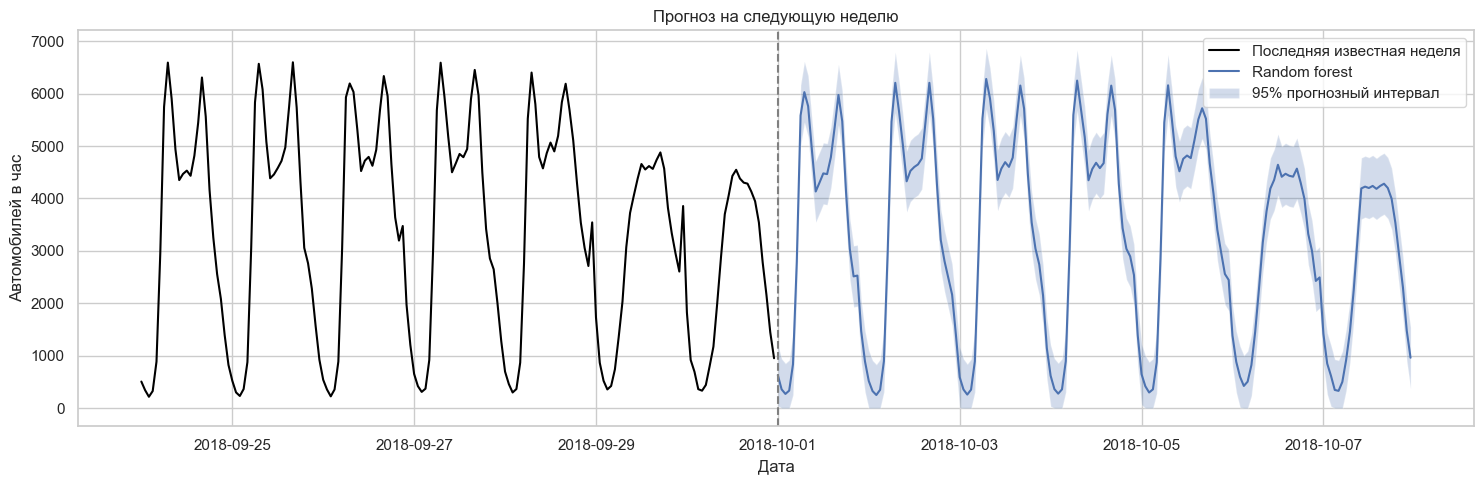

In [20]:
fig, ax = plt.subplots(figsize=(15, 5))
last_week = data['traffic_volume'].tail(HORIZON)
ax.plot(last_week.index, last_week, color='black', label='Последняя известная неделя')
ax.plot(future.index, future['traffic_volume'], label=best_name)
ax.fill_between(future.index, future['lower_95'], future['upper_95'],
                alpha=0.25, label='95% прогнозный интервал')
ax.axvline(future.index.min(), color='grey', linestyle='--')
ax.set(title='Прогноз на следующую неделю', ylabel='Автомобилей в час', xlabel='Дата')
ax.legend()
plt.tight_layout()
plt.show()

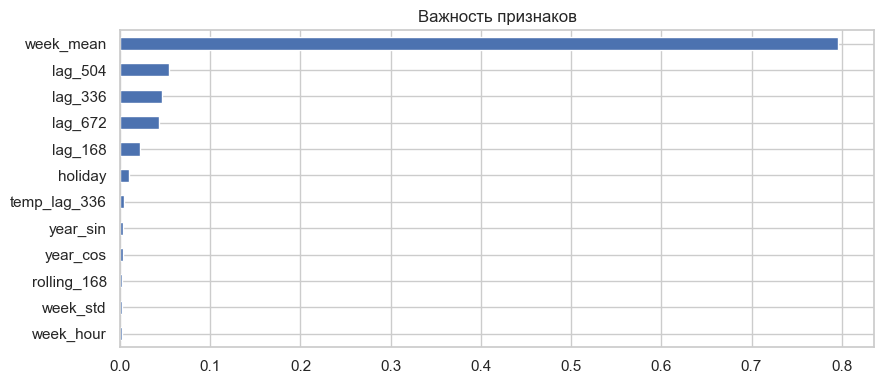

In [21]:
if final_model is not None and hasattr(final_model, 'feature_importances_'):
    importance = pd.Series(final_model.feature_importances_, index=X_example.columns)
    importance.nlargest(12).sort_values().plot.barh(figsize=(9, 4), title='Важность признаков')
    plt.tight_layout()
    plt.show()

## Вывод

Повторы часов удалены, ряд приведён к часовому шагу, пропуски заполнены линейно.
На валидации выбрали историю в 26 недель. Baseline сравнили с недельным повтором,
Ridge, случайным лесом и градиентным бустингом. На тесте лучше оказался случайный лес:
MAE 172,6 против 202,0 у baseline, улучшение 14,6%. На более ранней валидации лидировал baseline.
Случайный лес переобучен с включением тестовой части. Прогноз на 1–7 октября 2018 года
содержит 168 часов и приближённые 95% прогнозные интервалы.